In [3]:
from langgraph.graph import StateGraph, START, END
from langgraph.checkpoint.memory import InMemorySaver
from langchain_groq import ChatGroq
from typing import TypedDict
from dotenv import load_dotenv

In [4]:
load_dotenv()

True

In [5]:
llm = ChatGroq(model='qwen/qwen3.8-27b', max_tokens=500)

In [6]:
class JokeState(TypedDict):

    topic: str
    joke: str
    explaination: str

In [7]:
def generate_joke(state: JokeState):

    prompt = f'Generate a joke on topic - {state['topic']}'

    response = llm.invoke(prompt).content

    return {'joke': response}

In [8]:
def generate_explaination(state: JokeState):

    prompt = f'Generate an explaination of following joke - \n {state['joke']}'

    response = llm.invoke(prompt).content

    return {'explaination': response}

In [9]:
graph = StateGraph(JokeState)

graph.add_node('generate_joke', generate_joke)
graph.add_node('generate_explaination', generate_explaination)

graph.add_edge(START, 'generate_joke')
graph.add_edge('generate_joke', 'generate_explaination')
graph.add_edge('generate_explaination', END)

checkpointer = InMemorySaver()
workflow = graph.compile(checkpointer=checkpointer)

In [10]:
config = {'configurable': {'thread_id': "1"}}

workflow.invoke({'topic':'pizza'}, config=config)

{'topic': 'pizza',
 'joke': "Why did the pizza break up with the pepperoni?\n\nBecause it just couldn't handle the **topping** of their relationship! 🍕🌶️",
 'explaination': 'This joke relies on a **double meaning** (a pun) of the word **"topping."**\n\nHere’s the breakdown:\n\n1.  **Literal Meaning (Food):** In pizza terminology, "toppings" are the ingredients placed on top of the pizza dough, such as pepperoni, cheese, mushrooms, etc. So, the pepperoni is literally a "topping" on the pizza.\n\n2.  **Figurative Meaning (Relationships):** In relationships, "to top" someone can be slang for being dominant or taking control. More commonly, the phrase "can\'t handle the heat" or "can\'t take the pressure" is used to describe someone who is overwhelmed. Here, "topping" is used as a playful, slightly awkward substitute for "pressure," "stress," or "dominance." The joke suggests that the pizza was overwhelmed by the pepperoni’s presence or behavior.\n\nSo, the punchline plays on the idea that

In [11]:
workflow.get_state(config=config)

StateSnapshot(values={'topic': 'pizza', 'joke': "Why did the pizza break up with the pepperoni?\n\nBecause it just couldn't handle the **topping** of their relationship! 🍕🌶️", 'explaination': 'This joke relies on a **double meaning** (a pun) of the word **"topping."**\n\nHere’s the breakdown:\n\n1.  **Literal Meaning (Food):** In pizza terminology, "toppings" are the ingredients placed on top of the pizza dough, such as pepperoni, cheese, mushrooms, etc. So, the pepperoni is literally a "topping" on the pizza.\n\n2.  **Figurative Meaning (Relationships):** In relationships, "to top" someone can be slang for being dominant or taking control. More commonly, the phrase "can\'t handle the heat" or "can\'t take the pressure" is used to describe someone who is overwhelmed. Here, "topping" is used as a playful, slightly awkward substitute for "pressure," "stress," or "dominance." The joke suggests that the pizza was overwhelmed by the pepperoni’s presence or behavior.\n\nSo, the punchline pla

In [12]:
list(workflow.get_state_history(config=config))

[StateSnapshot(values={'topic': 'pizza', 'joke': "Why did the pizza break up with the pepperoni?\n\nBecause it just couldn't handle the **topping** of their relationship! 🍕🌶️", 'explaination': 'This joke relies on a **double meaning** (a pun) of the word **"topping."**\n\nHere’s the breakdown:\n\n1.  **Literal Meaning (Food):** In pizza terminology, "toppings" are the ingredients placed on top of the pizza dough, such as pepperoni, cheese, mushrooms, etc. So, the pepperoni is literally a "topping" on the pizza.\n\n2.  **Figurative Meaning (Relationships):** In relationships, "to top" someone can be slang for being dominant or taking control. More commonly, the phrase "can\'t handle the heat" or "can\'t take the pressure" is used to describe someone who is overwhelmed. Here, "topping" is used as a playful, slightly awkward substitute for "pressure," "stress," or "dominance." The joke suggests that the pizza was overwhelmed by the pepperoni’s presence or behavior.\n\nSo, the punchline pl

In [13]:
config2 = {'configurable': {'thread_id': "2"}}

workflow.invoke({'topic':'pasta'}, config=config2)

{'topic': 'pasta',
 'joke': "Why did the spaghetti break up with the macaroni?\n\nBecause things just weren't **al dente** anymore! 🍝",
 'explaination': 'Here is an explanation of the joke:\n\nThis is a **pun** based on a play on words involving cooking terminology and relationship dynamics.\n\n### The Key Phrase: "Al Dente"\n*   **Literal Meaning:** "Al dente" is Italian for "to the tooth." In cooking, it describes pasta (or rice) that is cooked to be firm and slightly resistant when bitten, rather than soft or mushy.\n*   **The Pun:** The phrase sounds very similar to the English phrase **"all done"** or, more poetically, **"all dented"** (implying damage or wear). However, the most direct humorous contrast here is between the *state* of the pasta and the *state* of the relationship.\n\n### Why It’s Funny:\n1.  **Personification:** The joke treats the spaghetti and macaroni like a romantic couple.\n2.  **The Breakup Reason:** Relationships often end when things "aren\'t what they use

In [14]:
list(workflow.get_state_history(config=config2))

[StateSnapshot(values={'topic': 'pasta', 'joke': "Why did the spaghetti break up with the macaroni?\n\nBecause things just weren't **al dente** anymore! 🍝", 'explaination': 'Here is an explanation of the joke:\n\nThis is a **pun** based on a play on words involving cooking terminology and relationship dynamics.\n\n### The Key Phrase: "Al Dente"\n*   **Literal Meaning:** "Al dente" is Italian for "to the tooth." In cooking, it describes pasta (or rice) that is cooked to be firm and slightly resistant when bitten, rather than soft or mushy.\n*   **The Pun:** The phrase sounds very similar to the English phrase **"all done"** or, more poetically, **"all dented"** (implying damage or wear). However, the most direct humorous contrast here is between the *state* of the pasta and the *state* of the relationship.\n\n### Why It’s Funny:\n1.  **Personification:** The joke treats the spaghetti and macaroni like a romantic couple.\n2.  **The Breakup Reason:** Relationships often end when things "a

## Time Travel

In [15]:
workflow.get_state({'configurable': {'thread_id': '2', 'checkpoint_ns': '', 'checkpoint_id': '1f1e3526-23e3-6470-8000-bb86b58443ac'}})

StateSnapshot(values={}, next=(), config={'configurable': {'thread_id': '2', 'checkpoint_ns': '', 'checkpoint_id': '1f1e3526-23e3-6470-8000-bb86b58443ac'}}, metadata=None, created_at=None, parent_config=None, tasks=(), interrupts=())

In [17]:
workflow.invoke(None, {'configurable': {'thread_id': '2', 'checkpoint_ns': '', 'checkpoint_id': '1f1e355f-d7a7-630d-8000-6a4f44ee1d98'}})

{'topic': 'pasta',
 'joke': 'Why did the spaghetti break up with the meatballs?\n\nBecause things were getting **too noodly**! 🍝',
 'explaination': 'This joke is a classic example of a **pun** (a play on words) combined with a **meme reference**. Here is the breakdown:\n\n### 1. The Setup\nThe joke personifies food items: spaghetti (noodles) and meatballs. It sets up a romantic relationship between them that is ending ("broke up").\n\n### 2. The Punchline\n> "Because things were getting **too noodly**!"\n\nThe humor comes from two layers:\n\n#### A. The Literal Meaning (Food Context)\nIn cooking, if you stir spaghetti and meatballs too aggressively or for too long, the spaghetti can break apart into smaller, mushy pieces. This is often described as the texture becoming "noodly" or "saucy" in a bad way. So, literally, the spaghetti is breaking down because the relationship (stirring) is getting messy.\n\n#### B. The Idiomatic Meaning (Slang Context)\nThe phrase **"things were getting we

In [18]:
list(workflow.get_state_history(config2))

[StateSnapshot(values={'topic': 'pasta', 'joke': 'Why did the spaghetti break up with the meatballs?\n\nBecause things were getting **too noodly**! 🍝', 'explaination': 'This joke is a classic example of a **pun** (a play on words) combined with a **meme reference**. Here is the breakdown:\n\n### 1. The Setup\nThe joke personifies food items: spaghetti (noodles) and meatballs. It sets up a romantic relationship between them that is ending ("broke up").\n\n### 2. The Punchline\n> "Because things were getting **too noodly**!"\n\nThe humor comes from two layers:\n\n#### A. The Literal Meaning (Food Context)\nIn cooking, if you stir spaghetti and meatballs too aggressively or for too long, the spaghetti can break apart into smaller, mushy pieces. This is often described as the texture becoming "noodly" or "saucy" in a bad way. So, literally, the spaghetti is breaking down because the relationship (stirring) is getting messy.\n\n#### B. The Idiomatic Meaning (Slang Context)\nThe phrase **"th

## Updating State

In [20]:
workflow.update_state({'configurable': {'thread_id': '1', 'checkpoint_ns': '', 'checkpoint_id': '1f1e355f-1af3-66fe-8000-79d28f862781'}}, {'topic':'samosa'})

{'configurable': {'thread_id': '1',
  'checkpoint_ns': '',
  'checkpoint_id': '1f1e3571-a04a-6a61-8001-4d45d2109255'}}

In [21]:
list(workflow.get_state_history(config))

[StateSnapshot(values={'topic': 'samosa'}, next=('generate_joke',), config={'configurable': {'thread_id': '1', 'checkpoint_ns': '', 'checkpoint_id': '1f1e3571-a04a-6a61-8001-4d45d2109255'}}, metadata={'source': 'update', 'step': 1, 'parents': {}}, created_at='2026-11-18T13:51:06.336911+00:00', parent_config={'configurable': {'thread_id': '1', 'checkpoint_ns': '', 'checkpoint_id': '1f1e355f-1af3-66fe-8000-79d28f862781'}}, tasks=(PregelTask(id='0537081d-311c-4e3e-4f0f-a3e88694ebad', name='generate_joke', path=('__pregel_pull', 'generate_joke'), error=None, interrupts=(), state=None, result=None),), interrupts=()),
 StateSnapshot(values={'topic': 'pizza', 'joke': "Why did the pizza break up with the pepperoni?\n\nBecause it just couldn't handle the **topping** of their relationship! 🍕🌶️", 'explaination': 'This joke relies on a **double meaning** (a pun) of the word **"topping."**\n\nHere’s the breakdown:\n\n1.  **Literal Meaning (Food):** In pizza terminology, "toppings" are the ingredien

In [22]:
workflow.invoke(None, {'configurable': {'thread_id': '1', 'checkpoint_ns': '', 'checkpoint_id': '1f1e3571-a04a-6a61-8001-4d45d2109255'}})

{'topic': 'samosa',
 'joke': 'Why did the samosa go to therapy?\n\nBecause it had too many **fillings** it couldn’t keep to itself! 🥟',
 'explaination': 'This joke is a classic example of a **pun** (a play on words) that relies on the double meaning of the word **"fillings."**\n\nHere’s the breakdown:\n\n### 1. The Literal Meaning (Food)\nA **samosa** is a popular savory pastry in South Asian cuisine. It is made by wrapping dough around a **filling** (usually spiced potatoes, peas, or meat). So, literally, a samosa *has* fillings inside it.\n\n### 2. The Figurative Meaning (Psychology)\nIn the context of **therapy**, "fillings" is not a standard term, but the joke plays on the idea of **emotional baggage**, **inner thoughts**, or **feelings** that a person is struggling to manage. The phrase *"couldn’t keep to itself"* suggests that the samosa is overwhelmed by its internal contents—just like a person might feel overwhelmed by their emotions, secrets, or mental clutter.\n\n### 3. The P

In [23]:
list(workflow.get_state_history(config))

[StateSnapshot(values={'topic': 'samosa', 'joke': 'Why did the samosa go to therapy?\n\nBecause it had too many **fillings** it couldn’t keep to itself! 🥟', 'explaination': 'This joke is a classic example of a **pun** (a play on words) that relies on the double meaning of the word **"fillings."**\n\nHere’s the breakdown:\n\n### 1. The Literal Meaning (Food)\nA **samosa** is a popular savory pastry in South Asian cuisine. It is made by wrapping dough around a **filling** (usually spiced potatoes, peas, or meat). So, literally, a samosa *has* fillings inside it.\n\n### 2. The Figurative Meaning (Psychology)\nIn the context of **therapy**, "fillings" is not a standard term, but the joke plays on the idea of **emotional baggage**, **inner thoughts**, or **feelings** that a person is struggling to manage. The phrase *"couldn’t keep to itself"* suggests that the samosa is overwhelmed by its internal contents—just like a person might feel overwhelmed by their emotions, secrets, or mental clut

## Fault Tolerance

In [26]:
import time

In [24]:
class CrashState(TypedDict):

    input: str
    step1: str
    step2: str
    step3: str

In [25]:
def step_1(state: CrashState):
    print("Step 1 executed")
    return {'step1': "done", 'input': state['input']}

In [27]:
def step_2(state: CrashState):
    print("step 2 hanging... now manually interrupt the execution")
    time.sleep(30)
    return {'step2': "done"}

In [28]:
def step_3(state: CrashState):
    print("Step 3 executed")
    return {'step3': "done"}

In [29]:
builder = StateGraph(CrashState)

builder.add_node('step_1', step_1)
builder.add_node('step_2', step_2)
builder.add_node('step_3', step_3)

builder.add_edge(START, 'step_1')
builder.add_edge('step_1', 'step_2')
builder.add_edge('step_2', 'step_3')
builder.add_edge('step_3',END)

checkpointer = InMemorySaver()

graph = builder.compile(checkpointer=checkpointer)

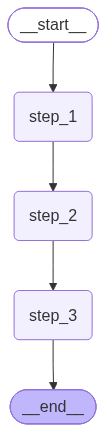

In [30]:
graph

In [31]:
graph.invoke({"input": "start"}, config={'configurable': {'thread_id': 'thread-1'}})

Step 1 executed
step 2 hanging... now manually interrupt the execution


KeyboardInterrupt: 

In [32]:
graph.get_state({'configurable': {'thread_id': 'thread-1'}})

StateSnapshot(values={'input': 'start', 'step1': 'done'}, next=('step_2',), config={'configurable': {'thread_id': 'thread-1', 'checkpoint_ns': '', 'checkpoint_id': '1f1e3674-b35f-69ab-8001-7677f3ff4e76'}}, metadata={'source': 'loop', 'step': 1, 'parents': {}}, created_at='2026-11-18T15:47:00.816110+00:00', parent_config={'configurable': {'thread_id': 'thread-1', 'checkpoint_ns': '', 'checkpoint_id': '1f1e3674-b35d-647e-8000-3cb0e340e0fc'}}, tasks=(PregelTask(id='34966f01-b689-cd1b-c94f-b4eca217dc2d', name='step_2', path=('__pregel_pull', 'step_2'), error=None, interrupts=(), state=None, result=None),), interrupts=())

In [34]:
list(graph.get_state_history({'configurable': {'thread_id': 'thread-1'}}))

[StateSnapshot(values={'input': 'start', 'step1': 'done'}, next=('step_2',), config={'configurable': {'thread_id': 'thread-1', 'checkpoint_ns': '', 'checkpoint_id': '1f1e3674-b35f-69ab-8001-7677f3ff4e76'}}, metadata={'source': 'loop', 'step': 1, 'parents': {}}, created_at='2026-11-18T15:47:00.816110+00:00', parent_config={'configurable': {'thread_id': 'thread-1', 'checkpoint_ns': '', 'checkpoint_id': '1f1e3674-b35d-647e-8000-3cb0e340e0fc'}}, tasks=(PregelTask(id='34966f01-b689-cd1b-c94f-b4eca217dc2d', name='step_2', path=('__pregel_pull', 'step_2'), error=None, interrupts=(), state=None, result=None),), interrupts=()),
 StateSnapshot(values={'input': 'start'}, next=('step_1',), config={'configurable': {'thread_id': 'thread-1', 'checkpoint_ns': '', 'checkpoint_id': '1f1e3674-b35d-647e-8000-3cb0e340e0fc'}}, metadata={'source': 'loop', 'step': 0, 'parents': {}}, created_at='2026-11-18T15:47:00.815156+00:00', parent_config={'configurable': {'thread_id': 'thread-1', 'checkpoint_ns': '', 'ch

In [35]:
graph.invoke(None, {'configurable': {'thread_id': 'thread-1'}})

step 2 hanging... now manually interrupt the execution
Step 3 executed


{'input': 'start', 'step1': 'done', 'step2': 'done', 'step3': 'done'}

In [36]:
list(graph.get_state_history({'configurable': {'thread_id': 'thread-1'}}))

[StateSnapshot(values={'input': 'start', 'step1': 'done', 'step2': 'done', 'step3': 'done'}, next=(), config={'configurable': {'thread_id': 'thread-1', 'checkpoint_ns': '', 'checkpoint_id': '1f1e367a-3449-6236-8003-52933ca6fd01'}}, metadata={'source': 'loop', 'step': 3, 'parents': {}}, created_at='2026-11-18T15:49:28.551256+00:00', parent_config={'configurable': {'thread_id': 'thread-1', 'checkpoint_ns': '', 'checkpoint_id': '1f1e367a-3444-6688-8002-d94c2cd609db'}}, tasks=(), interrupts=()),
 StateSnapshot(values={'input': 'start', 'step1': 'done', 'step2': 'done'}, next=('step_3',), config={'configurable': {'thread_id': 'thread-1', 'checkpoint_ns': '', 'checkpoint_id': '1f1e367a-3444-6688-8002-d94c2cd609db'}}, metadata={'source': 'loop', 'step': 2, 'parents': {}}, created_at='2026-11-18T15:49:28.549295+00:00', parent_config={'configurable': {'thread_id': 'thread-1', 'checkpoint_ns': '', 'checkpoint_id': '1f1e3674-b35f-69ab-8001-7677f3ff4e76'}}, tasks=(PregelTask(id='eeee1ba6-6e7b-929b